# Signals and Feature Engineering

Condition monitoring systems record vibration, current, pressure or acoustic signals at sampling rates of several kilohertz. A single minute of vibration data from one accelerometer at 12 kHz contains 720,000 numbers. Machine learning models cannot – and should not – work on such raw data directly. They need a small set of **features** that capture the information relevant for the question at hand.

This chapter shows how to get from a raw signal to meaningful features. We look at signals in the time and in the frequency domain, use the physics of rolling bearings to know *where* in the spectrum a fault should appear, and compute statistical features that summarise a signal window. Feature engineering is where engineering knowledge pays off most in data science.

::: {.scenario}
**Scenario: a cheap sensor for the pump station**

A water utility operates dozens of pumps with rolling bearings. A full condition monitoring system is too expensive, but the maintenance team could fit each pump with a low-cost vibration sensor that computes a single number per second and raises an alarm above a threshold. The team asks: which number, which threshold – and will it work?

**Your decision:** Is a simple threshold on one statistical feature good enough to detect an inner-race fault, and which threshold do you set?
:::

**Learning goals.** After this chapter you can

- explain sampling, the Nyquist frequency and aliasing,
- compute and interpret amplitude spectra with the FFT, including frequency resolution and leakage,
- calculate characteristic bearing fault frequencies and relate spectral peaks to them,
- extract statistical features (RMS, peak, crest factor, kurtosis) from signal windows,
- split windowed data correctly for training and testing,
- (extension) explain and apply envelope analysis.

**Datasets in this chapter**

- [CWRU Bearing Data Center](https://engineering.case.edu/bearingdatacenter)
- [Condition Monitoring of Hydraulic Systems (UCI)](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)

## Sampling and aliasing

A sensor signal is continuous; the data acquisition system samples it at discrete times $t_n = n/f_s$ with the **sampling rate** $f_s$.

::: {.callout-important}
## Sampling theorem (Nyquist–Shannon)
A signal can be reconstructed from its samples if it contains no frequencies at or above half the sampling rate, the **Nyquist frequency** $f_N = f_s/2$. Frequencies above $f_N$ are not lost silently – they are folded back and appear as false lower frequencies (**aliasing**).
:::

![Aliasing. A 9 Hz sine sampled at 10 Hz (dots) produces exactly the same samples as a 1 Hz sine. After sampling, the two cannot be distinguished.](images/aliasing.png){#fig-aliasing width=85%}

A component at frequency $f$ with $f_N < f < f_s$ appears at $|f - f_s|$. This is why data acquisition systems use an analogue **anti-aliasing filter** before the A/D converter. Once aliasing has happened, no digital processing can undo it.

## The frequency domain

Rotating machines produce periodic excitations: imbalance at the shaft frequency, gear meshing at the tooth frequency, bearing defects at characteristic frequencies. In the time domain these components overlap; in the frequency domain they separate into peaks.

::: {.callout-note}
## Definition: Discrete Fourier transform and amplitude spectrum
For $N$ samples $x_0, \dots, x_{N-1}$, the discrete Fourier transform is
$$X_k = \sum_{n=0}^{N-1} x_n\, e^{-2\pi i\,kn/N}, \qquad k = 0, \dots, N-1,$$
computed efficiently by the **fast Fourier transform (FFT)**. Bin $k$ corresponds to the frequency $f_k = k\,f_s/N$. The single-sided **amplitude spectrum** $A_k = 2|X_k|/N$ (for $0 < k < N/2$) gives the amplitude of a sine component at $f_k$.
:::

Two practical facts:

- **Frequency resolution** $\Delta f = f_s/N = 1/T$: it depends only on the measurement duration $T$. To separate two peaks 1 Hz apart, you need at least one second of data.
- **Leakage:** the FFT assumes the signal window repeats periodically. If a component does not complete an integer number of periods in the window, its energy "leaks" into neighbouring bins. Multiplying the window by a smooth **window function** (e.g. Hann) reduces leakage at the price of slightly wider peaks.

## Bearing fault frequencies

When a rolling element passes a local defect on a raceway, it produces a short impact. These impacts repeat at frequencies that follow from the bearing geometry: with shaft frequency $f_r$, number of rolling elements $n_b$, rolling element diameter $d$, pitch diameter $D$ and contact angle $\phi$,

$$\text{BPFO} = \frac{n_b f_r}{2}\left(1 - \frac{d}{D}\cos\phi\right), \qquad \text{BPFI} = \frac{n_b f_r}{2}\left(1 + \frac{d}{D}\cos\phi\right).$$

BPFO and BPFI are the *ball pass frequencies* of the outer and inner race. For the drive-end bearing of the CWRU test rig (SKF 6205), the CWRU documentation gives BPFI ≈ 5.415 $f_r$ and BPFO ≈ 3.585 $f_r$ – check the bearing specification page before relying on these factors.

::: {.callout-tip}
## Engineering practice: let physics tell you where to look
Knowing the fault frequencies turns a vague search ("is the spectrum different?") into a targeted test ("is there a peak at BPFI and its harmonics?"). Features built from physics – the amplitude at BPFI, the energy in a resonance band – are more robust and easier to explain than features found by blind search.
:::

## Statistical features of a signal window

::: {.callout-note}
## Definition: Common time-domain features
For a window $x_1, \dots, x_N$:

- **RMS** $= \sqrt{\frac{1}{N}\sum x_i^2}$ – overall vibration energy,
- **peak** $= \max |x_i|$,
- **crest factor** $=$ peak / RMS – impulsiveness,
- **kurtosis** $= m_4/m_2^2 - 3$ (excess kurtosis), with the central moments $m_r = \frac1N\sum_{i=1}^N (x_i - \bar x)^r$ – "spikiness"; 0 for a normal distribution, large for signals with short impacts,
- **skewness** – asymmetry of the amplitude distribution.
:::

Early bearing damage produces short impacts: kurtosis and crest factor rise while the RMS hardly changes. As damage progresses and spreads, the impacts become less distinct, kurtosis may fall again and RMS rises – a reason to use several features together.

::: {.callout-warning}
## Pitfall: splitting windows of the same recording
When a long recording is cut into windows, neighbouring windows are almost identical. If windows of the same recording end up in both training and test set, the model recognises the *recording*, not the fault – the test accuracy is meaningless. Split by recording, machine or time period (e.g. with `GroupKFold`), never randomly by window.
:::

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from scipy.io import loadmat

sns.set_theme(style="whitegrid")

In [2]:
#| code-fold: false
# Download helper, as in Chapter 2
from pathlib import Path
import requests

DATA = Path("data")
DATA.mkdir(exist_ok=True)                         # create the folder ./data if it does not exist

def download(url, fname=None):
    """Download a file once and cache it in ./data."""
    if fname is None:                             # no file name given:
        fname = url.split("/")[-1]                # use the last part of the URL
    path = DATA / fname                           # "/" joins folder and file name
    if not path.exists():                         # download only if not cached yet
        r = requests.get(url, timeout=120)        # give up after 120 s without response
        r.raise_for_status()                      # stop with an error if the download failed
        path.write_bytes(r.content)               # open, write and close the file in one step
    return path

## Live coding: healthy vs. inner-race fault

The Case Western Reserve University (CWRU) bearing data are a widely used benchmark. Faults of defined size were introduced into the bearings of a 2 hp motor test rig by electro-discharge machining; vibration was measured with accelerometers at the drive end and fan end. We use two files: normal baseline (`97.mat`) and a 0.007-inch inner race fault at the drive end (`105.mat`), both at 0 hp motor load (approx. 1797 rpm).

**Check the file numbers and the sampling rates (12 kHz or 48 kHz) on the CWRU download pages before using them** – the values below are set accordingly and marked.

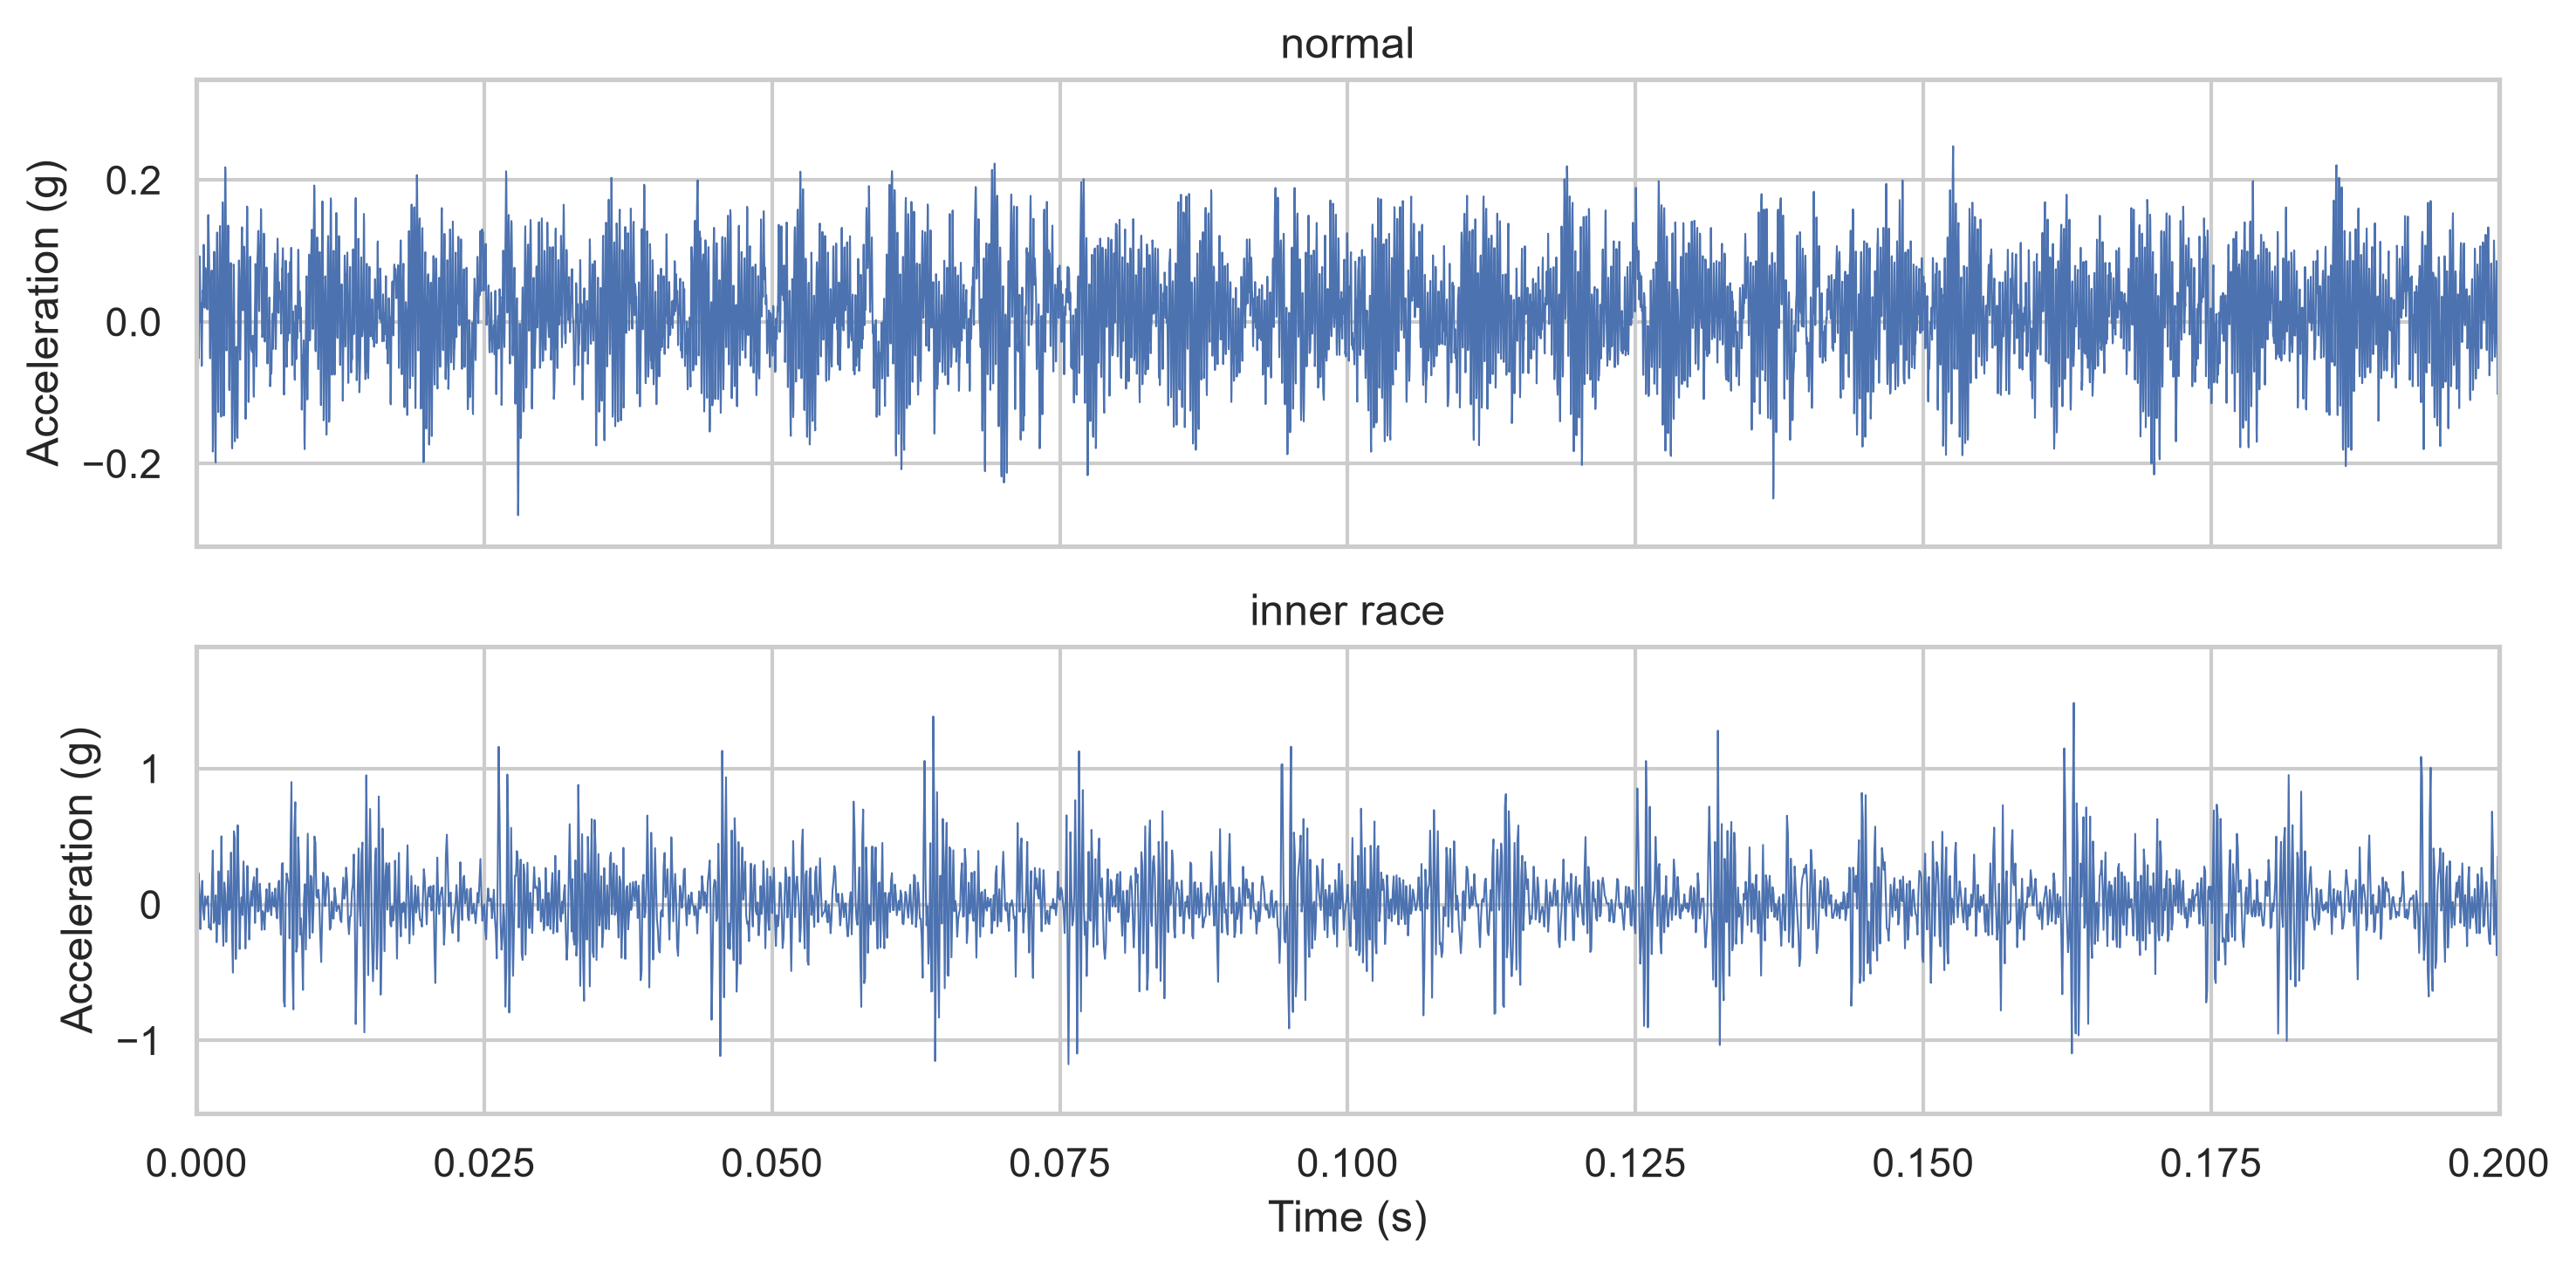

In [3]:
#| code-fold: false
FILES = {"normal": ("97.mat", 48_000), "inner race": ("105.mat", 12_000)}   # file, sampling rate (Hz) – verify!
BASE_URL = "https://engineering.case.edu/sites/default/files/"

signals = {}
for label, (fname, fs) in FILES.items():
    mat = loadmat(download(BASE_URL + fname))
    key = next(k for k in mat if k.endswith("_DE_time"))     # drive-end accelerometer
    signals[label] = (mat[key].ravel(), fs)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, (label, (x, fs)) in zip(axes, signals.items()):
    t = np.arange(len(x)) / fs
    ax.plot(t, x, lw=0.5); ax.set(title=label, ylabel="Acceleration (g)")
axes[1].set(xlim=(0, 0.2), xlabel="Time (s)")
plt.tight_layout(); plt.show()

**Discussion.** Already in the time domain the faulty bearing looks different: short, regularly spaced impacts are visible on top of the background vibration. Count the impacts in 0.1 s – their rate should match the BPFI of about 5.4 × 30 Hz ≈ 162 Hz.

## Live coding: amplitude spectrum

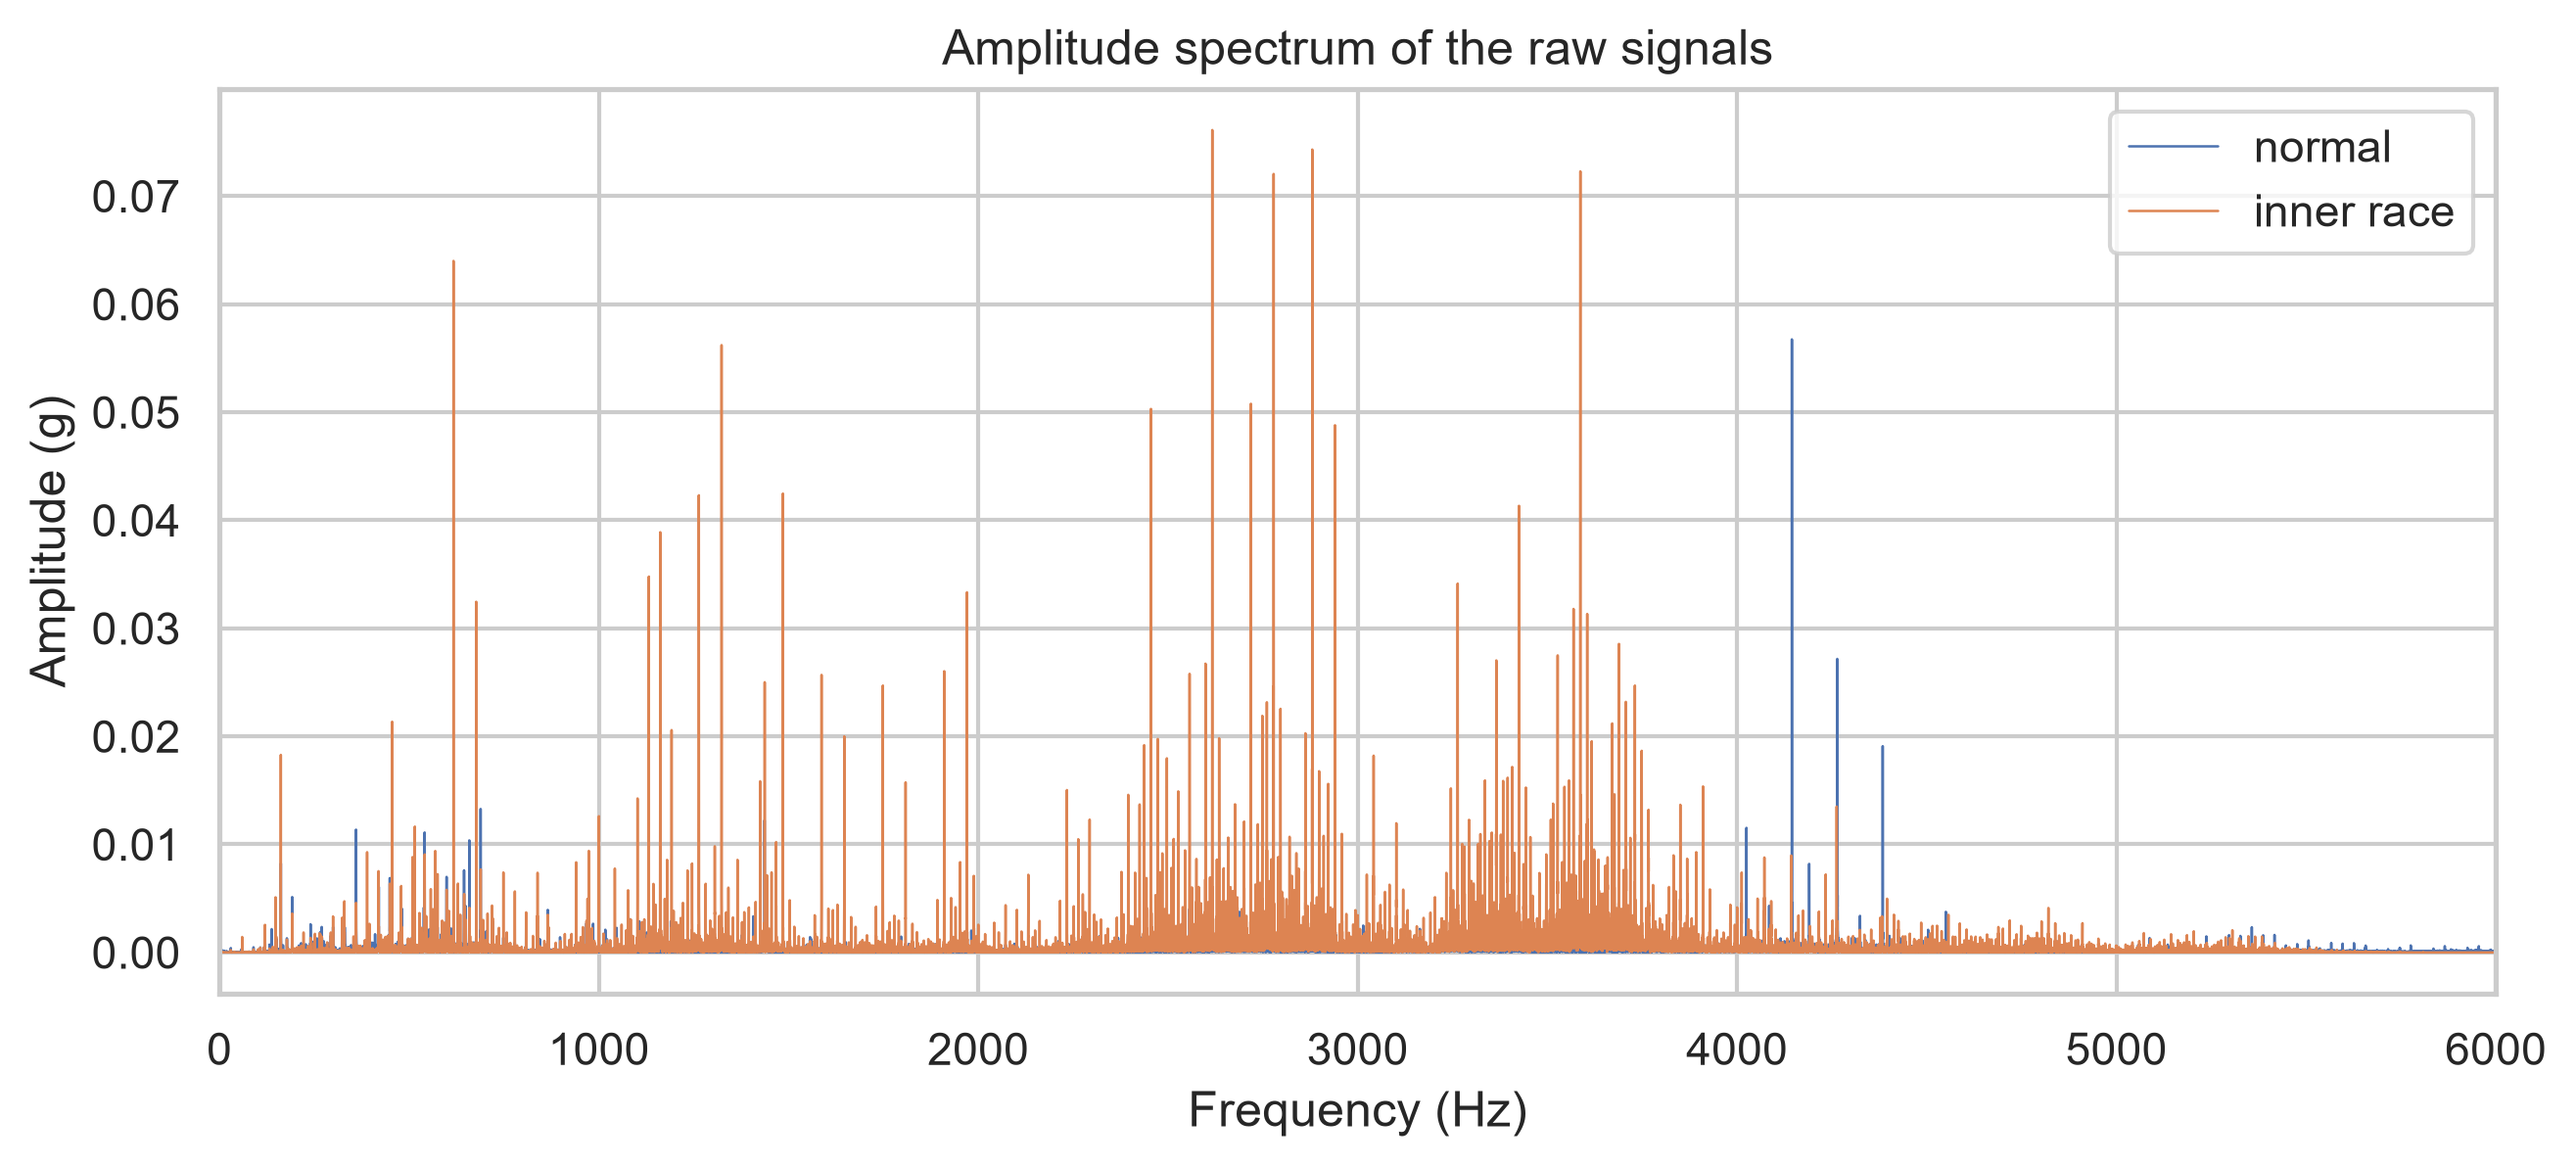

In [4]:
#| code-fold: false
fig, ax = plt.subplots(figsize=(10, 4))
for label, (x, fs) in signals.items():
    f = np.fft.rfftfreq(len(x), 1 / fs)
    A = 2 * np.abs(np.fft.rfft(x)) / len(x)
    ax.plot(f, A, label=label, lw=0.6)
ax.set(xlim=(0, 6000), xlabel="Frequency (Hz)", ylabel="Amplitude (g)",
       title="Amplitude spectrum of the raw signals")
ax.legend(); plt.show()

**Discussion.** The faulty bearing shows much more energy at high frequencies, in the range of several kilohertz. These are **structural resonances** of the bearing and housing, excited by the impacts – not the fault frequency itself. The impact rate of about 162 Hz modulates these resonances but is hard to see directly in this spectrum. Envelope analysis makes it visible.

## Extension: envelope analysis

*Extension – optional material, not required for the exam.*

![Envelope analysis. Periodic impacts excite a high-frequency resonance (1). A band-pass filter isolates the resonance band (2). The envelope – the magnitude of the analytic signal from the Hilbert transform – recovers the impact pattern (3). Its spectrum shows peaks at the impact frequency and its harmonics (4).](images/envelope.png){#fig-envelope width=100%}

The plain spectrum shows *that* the faulty bearing excites high-frequency resonances, but not *why*. The envelope spectrum reveals the repetition rate of the impacts – and thus the damaged component.

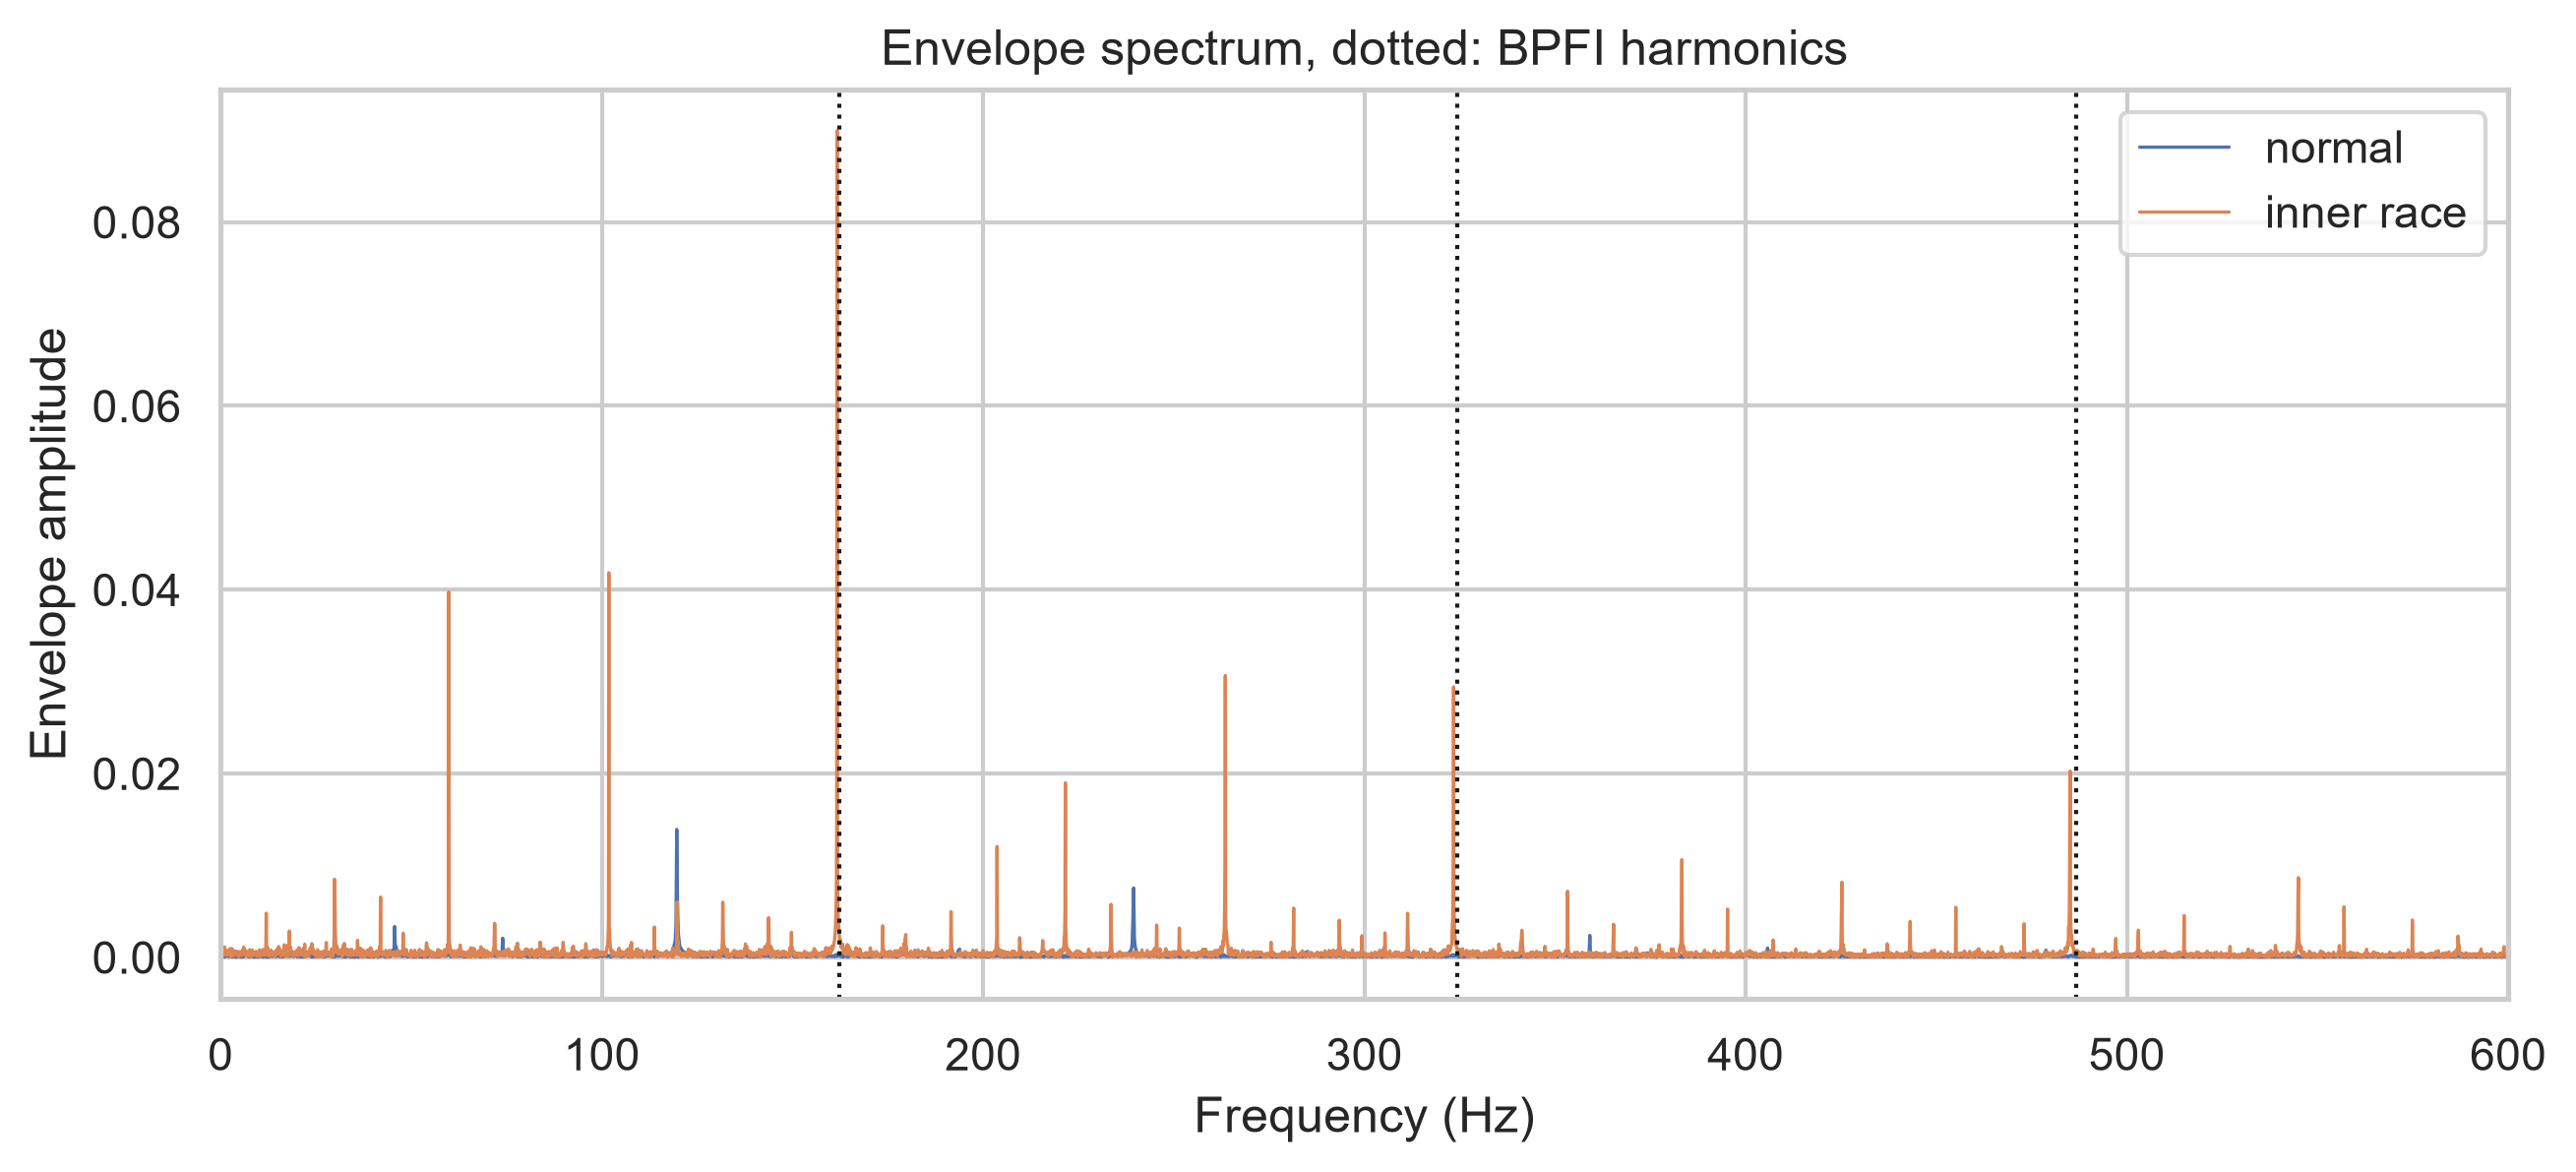

In [5]:
#| code-fold: false
f_r = 1797 / 60          # shaft frequency (Hz)
bpfi = 5.4152 * f_r

def envelope_spectrum(x, fs, band=(2000, 5000)):
    b, a = signal.butter(4, band, btype="bandpass", fs=fs)
    env = np.abs(signal.hilbert(signal.filtfilt(b, a, x)))
    env -= env.mean()
    f = np.fft.rfftfreq(len(env), 1 / fs)
    return f, np.abs(np.fft.rfft(env)) / len(env)

fig, ax = plt.subplots(figsize=(10, 4))
for label, (x, fs) in signals.items():
    f, A = envelope_spectrum(x, fs)
    ax.plot(f, A, label=label, lw=0.8)
for k in (1, 2, 3):
    ax.axvline(k * bpfi, c="k", ls=":", lw=1)
ax.set(xlim=(0, 600), xlabel="Frequency (Hz)", ylabel="Envelope amplitude",
       title="Envelope spectrum, dotted: BPFI harmonics")
ax.legend(); plt.show()

For the inner race fault, peaks appear at BPFI and its harmonics; often there are also sidebands spaced at the shaft frequency, because the defect on the rotating inner ring moves in and out of the load zone once per revolution. The choice of the band (here 2–5 kHz) matters: it should contain the resonance excited by the impacts. Methods such as the *kurtogram* select it automatically.

## Live coding: statistical features

In [6]:
#| code-fold: false
def features(x):
    rms = np.sqrt(np.mean(x**2))
    return {"rms": rms, "peak": np.max(np.abs(x)), "crest": np.max(np.abs(x)) / rms,
            "kurtosis": stats.kurtosis(x), "skewness": stats.skew(x)}

# features on 1-second windows
rows = []
for label, (x, fs) in signals.items():
    for start in range(0, len(x) - fs, fs):
        rows.append({"condition": label, **features(x[start:start + fs])})
feat = pd.DataFrame(rows)
feat.groupby("condition").mean().round(3)

,rms,peak,crest,kurtosis,skewness
condition,,,,,
inner race,0.291,1.601,5.494,2.397,0.164
normal,0.074,0.279,3.787,-0.235,-0.035


**Discussion.** The faulty bearing has a clearly higher kurtosis and crest factor – the signature of impacts. Such features can feed a classifier (Exercise 3). They are cheap to compute, which matters for monitoring systems running on embedded hardware, and they have an intuitive meaning that maintenance staff understand.

## Back to the decision

A single-feature threshold works if the feature values of healthy and faulty windows do not overlap. We check kurtosis and crest factor and, if they separate, place the threshold in the middle of the gap.

In [7]:
#| code-fold: false
for f_name in ["kurtosis", "crest"]:
    healthy_max = feat.loc[feat.condition == "normal", f_name].max()
    faulty_min = feat.loc[feat.condition == "inner race", f_name].min()
    if faulty_min > healthy_max:
        print(f"{f_name:9s}: separates (healthy max {healthy_max:.2f} < faulty min {faulty_min:.2f}) "
              f"-> threshold {(healthy_max + faulty_min) / 2:.2f}")
    else:
        print(f"{f_name:9s}: overlap (healthy max {healthy_max:.2f} >= faulty min {faulty_min:.2f})")

kurtosis : separates (healthy max -0.20 < faulty min 2.05) -> threshold 0.92
crest    : separates (healthy max 4.27 < faulty min 5.15) -> threshold 4.71


If a feature separates the two recordings, the decision looks easy – but it rests on **one** healthy and **one** faulty recording at one load. Before ordering sensors for dozens of pumps, the threshold must be checked on other loads, other fault types and sizes, and above all on healthy pumps in the field, whose kurtosis can be raised by cavitation or electrical interference. The recommendation is therefore: a pilot on a few pumps with the chosen feature, logging the values for some months before alarms are switched on.

::: {.callout-important}
## Key takeaways
- Sample at more than twice the highest relevant frequency and filter before sampling – aliasing cannot be undone.
- The FFT reveals periodic components; frequency resolution is $1/T$, leakage is reduced by window functions.
- Bearing geometry determines where fault frequencies appear; physics-based features are robust and explainable.
- RMS, crest factor and kurtosis summarise signal windows; split windows by recording, not randomly.
:::

## Exercises

<div class="exercises">

1. A vibration signal contains a component at 7 kHz. It is sampled at 10 kHz without anti-aliasing filter. At which frequency does the component appear in the spectrum? What sampling rate would be needed?
2. You record 0.5 s of vibration data at 12 kHz. What is the frequency resolution? Can you separate the BPFI (≈ 162.3 Hz) from its sideband at BPFI + $f_r$?
3. Build a classifier for normal / inner race / ball / outer race faults on the statistical window features. Split each recording in time (first 70 % of the windows for training, last 30 % for testing). Why is a random split of the windows wrong?
4. Hydraulic system: compute features per cycle (mean, std, max) for the 100 Hz pressure sensors and predict the valve condition with a random forest. Use stratified cross-validation.
5. (Extension) Compare the plain amplitude spectrum with the envelope spectrum around BPFI. Then download an outer race fault file and check whether a peak appears at BPFO.

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1
The Nyquist frequency is 5 kHz. The 7 kHz component is folded back to $|7 - 10| = 3$ kHz – it appears as a false peak at 3 kHz. To capture 7 kHz correctly, the sampling rate must exceed 14 kHz; in practice one chooses about 2.5 times the highest frequency of interest (≥ 17.5 kHz) and uses an anti-aliasing filter with its cut-off below the Nyquist frequency.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2
$\Delta f = 1/T = 1/0.5\,\text{s} = 2$ Hz. The sideband lies $f_r \approx 30$ Hz from the BPFI peak, i.e. 15 bins away – easily separable. Peaks closer than about 2–3 bins (here 4–6 Hz) could not be separated, especially with a window function that widens the peaks. Note that the sampling rate does not affect the resolution; only the duration does.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [8]:
#| code-fold: false
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

FILES4 = {"normal": ("97.mat", 48_000), "inner race": ("105.mat", 12_000),
          "ball": ("118.mat", 12_000), "outer race": ("130.mat", 12_000)}   # verify on the CWRU pages!
rows = []
for label, (fname, fs) in FILES4.items():
    mat = loadmat(download(BASE_URL + fname))
    x = mat[next(k for k in mat if k.endswith("_DE_time"))].ravel()
    if fs == 48_000:                                   # bring all signals to 12 kHz
        x, fs = signal.decimate(x, 4), 12_000
    win = fs // 4                                      # 0.25 s windows
    starts = range(0, len(x) - win, win)
    n_train = int(0.7 * len(starts))
    for i, s in enumerate(starts):
        rows.append({"condition": label, "train": i < n_train, **features(x[s:s + win])})
fw = pd.DataFrame(rows)
feat_cols = ["rms", "peak", "crest", "kurtosis", "skewness"]
clf = RandomForestClassifier(300, random_state=0).fit(fw.loc[fw.train, feat_cols], fw.loc[fw.train, "condition"])
print(classification_report(fw.loc[~fw.train, "condition"], clf.predict(fw.loc[~fw.train, feat_cols])))

              precision    recall  f1-score   support

        ball       1.00      1.00      1.00        12
  inner race       1.00      1.00      1.00        12
      normal       1.00      1.00      1.00         6
  outer race       1.00      1.00      1.00        12

    accuracy                           1.00        42
   macro avg       1.00      1.00      1.00        42
weighted avg       1.00      1.00      1.00        42



All signals are first brought to the same sampling rate, because features such as peak and RMS depend on the bandwidth. A random split would put neighbouring, nearly identical windows into training and test, so the test accuracy would measure memorisation. The time split is better, but still optimistic: there is only one recording per condition, so the model may learn properties of the individual test run (sensor mounting, load) rather than the fault. A convincing evaluation needs several recordings per class – e.g. train on 0 and 1 hp, test on 2 and 3 hp.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [9]:
#| code-fold: false
import zipfile
from sklearn.model_selection import cross_val_score, StratifiedKFold

hz = download("https://archive.ics.uci.edu/static/public/447/condition+monitoring+of+hydraulic+systems.zip",
              "hydraulic.zip")

def read_sensor(z, name):
    member = next(n for n in z.namelist() if n.endswith(name))
    return pd.read_csv(z.open(member), sep="\t", header=None).values

with zipfile.ZipFile(hz) as z:
    ps = {s: read_sensor(z, f"{s}.txt") for s in ["PS1", "PS2", "PS3", "PS4", "PS5", "PS6"]}
    profile = pd.DataFrame(read_sensor(z, "profile.txt"),
                           columns=["cooler", "valve", "pump_leak", "accumulator", "stable"])
feat_ps = pd.DataFrame({f"{s}_{stat}": getattr(np, stat)(v, axis=1)
                        for s, v in ps.items() for stat in ["mean", "std", "max"]})
acc = cross_val_score(RandomForestClassifier(300, random_state=0), feat_ps, profile["valve"].astype(int),
                      cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(f"Valve condition accuracy: {acc.mean():.3f} ± {acc.std():.3f}")

Valve condition accuracy: 0.987 ± 0.008


Simple pressure statistics per cycle usually predict the valve condition well, because a degraded valve changes the switching behaviour and thus the pressure curves. Caution: the conditions were changed in blocks over the duration of the experiment, so neighbouring cycles share conditions *and* drifting factors such as oil temperature. A time-based split would give a more conservative estimate than the shuffled cross-validation used here.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

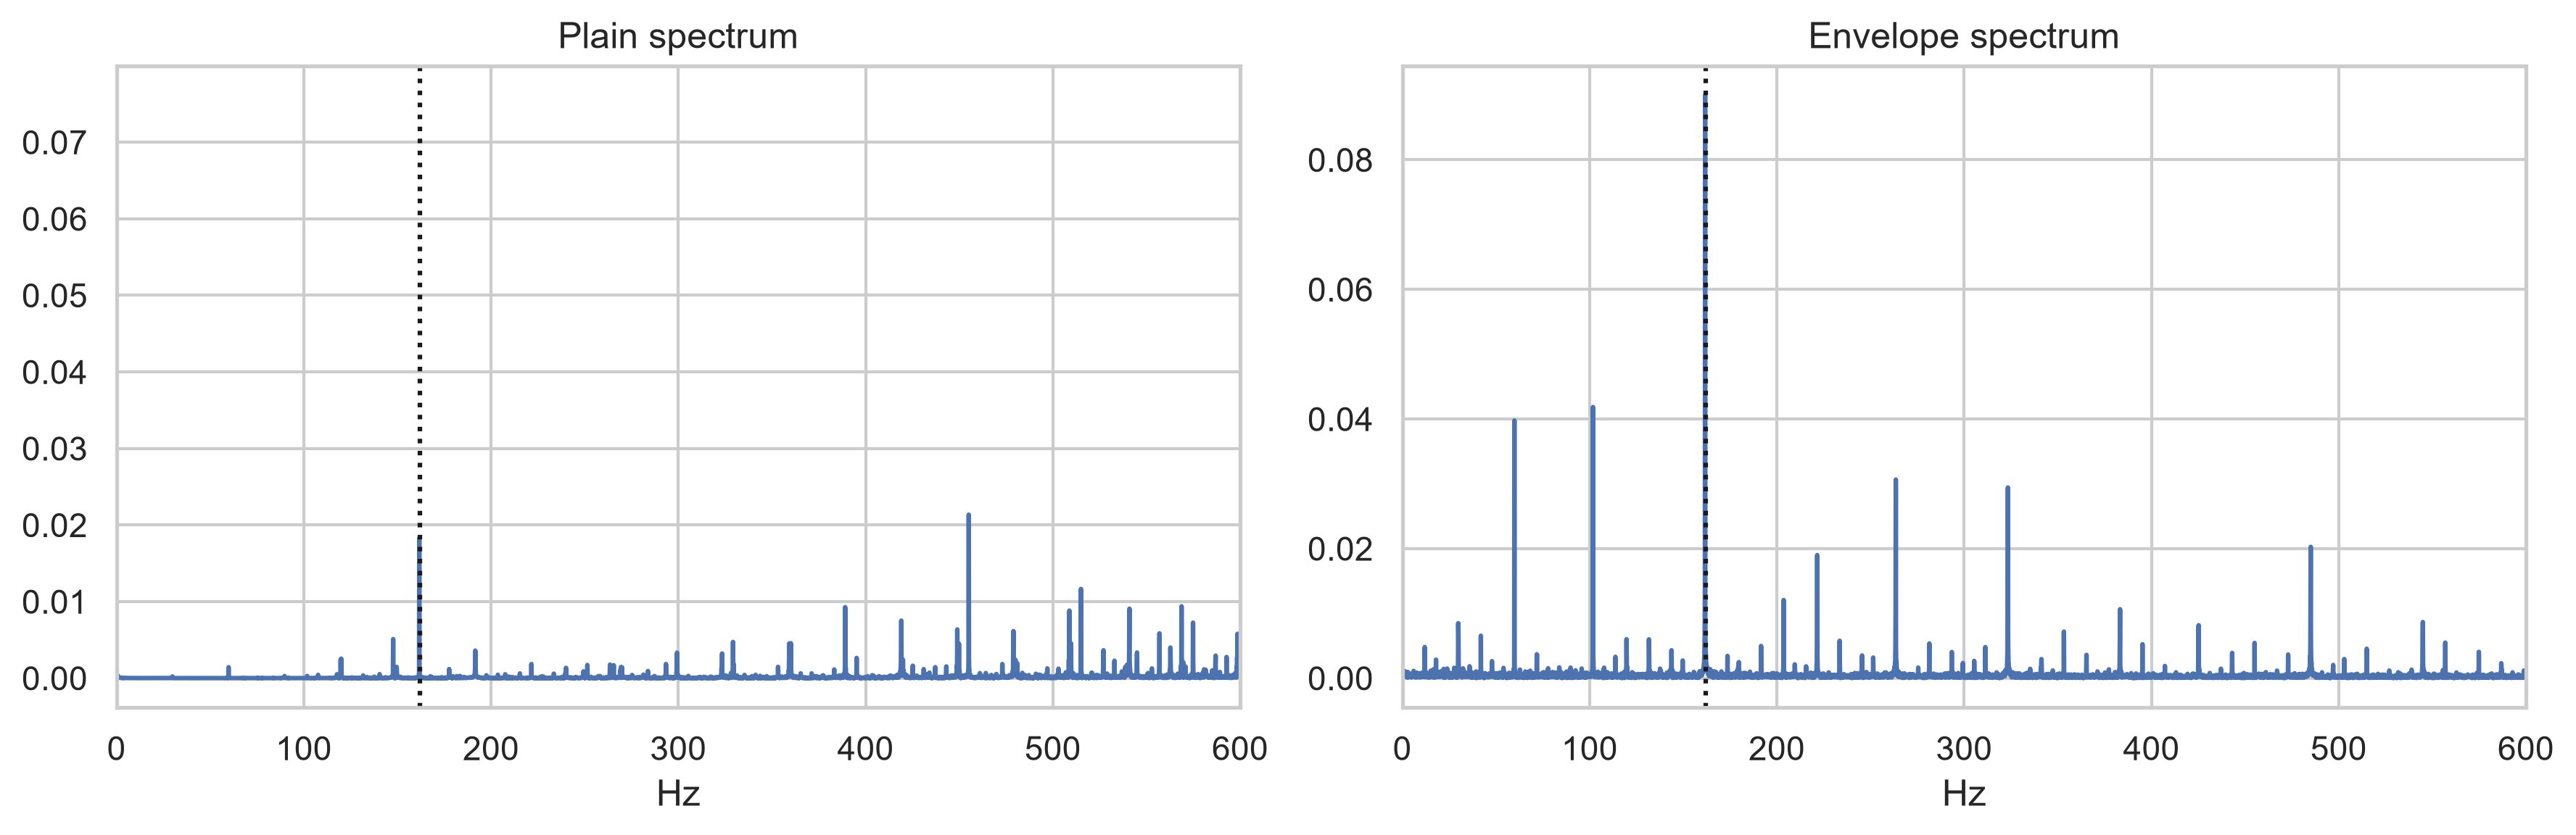

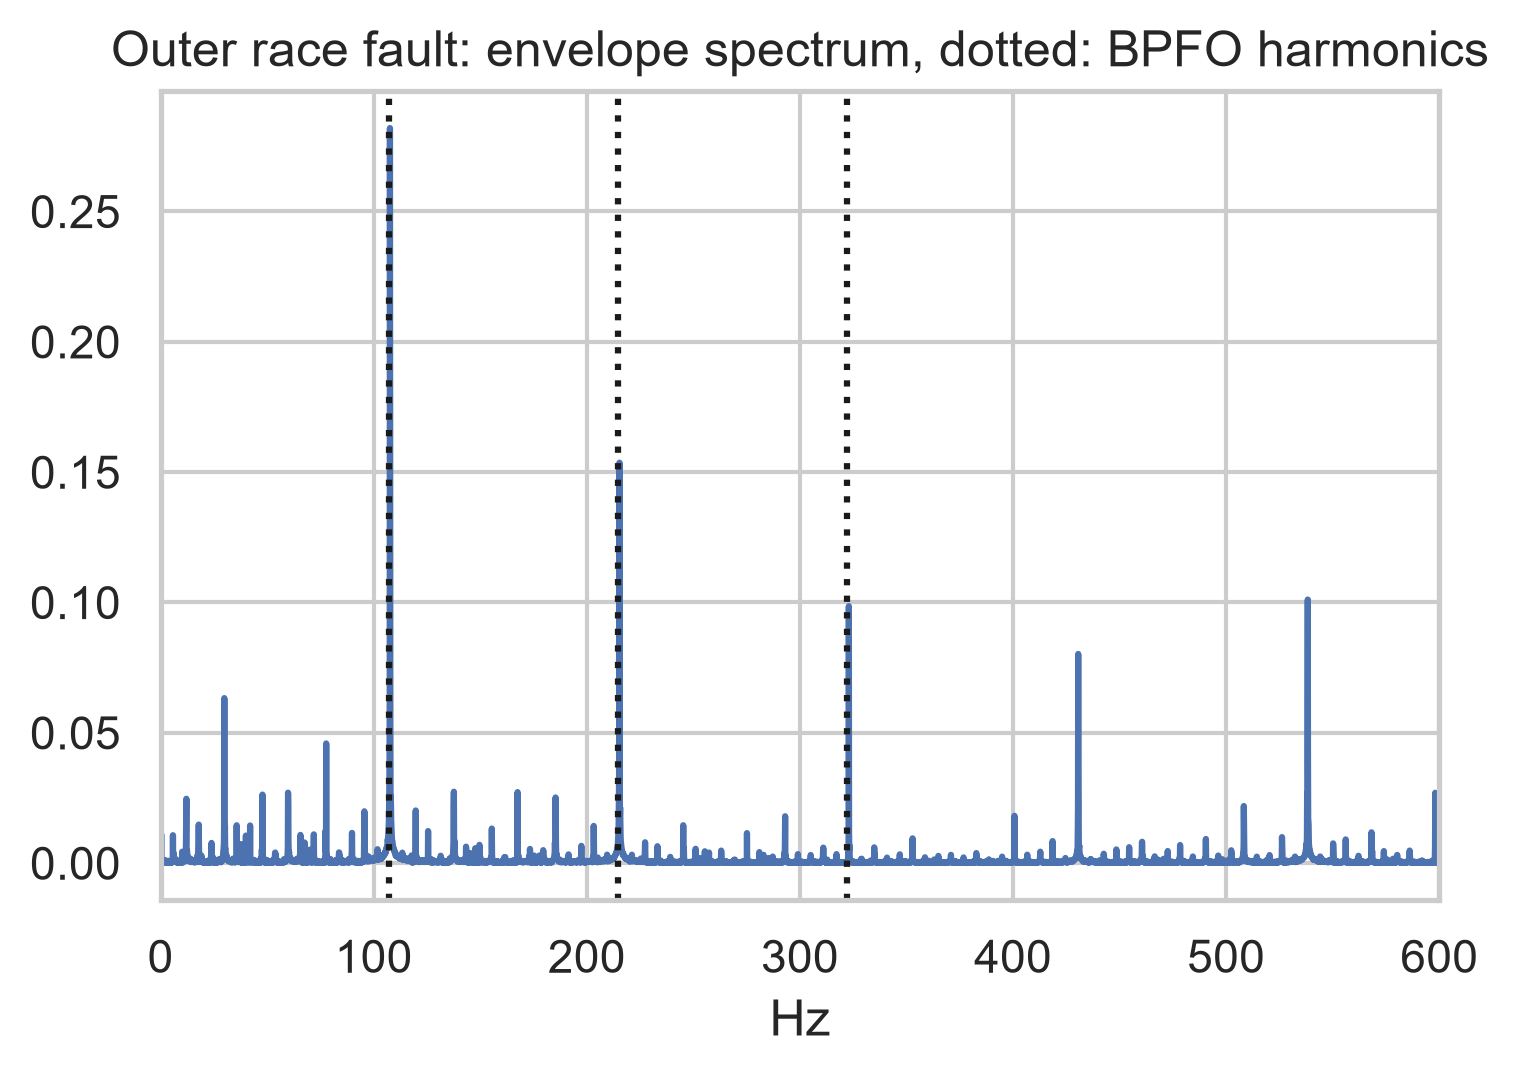

In [10]:
#| code-fold: false
x_ir, fs_ir = signals["inner race"]
f_plain = np.fft.rfftfreq(len(x_ir), 1 / fs_ir)
A_plain = 2 * np.abs(np.fft.rfft(x_ir)) / len(x_ir)
f_env, A_env = envelope_spectrum(x_ir, fs_ir)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(f_plain, A_plain); axes[0].set(xlim=(0, 600), title="Plain spectrum", xlabel="Hz")
axes[1].plot(f_env, A_env); axes[1].set(xlim=(0, 600), title="Envelope spectrum", xlabel="Hz")
for ax in axes:
    ax.axvline(bpfi, c="k", ls=":")
plt.tight_layout(); plt.show()

mat = loadmat(download(BASE_URL + "130.mat"))                 # outer race fault (verify!)
x_or = mat[next(k for k in mat if k.endswith("_DE_time"))].ravel()
f_o, A_o = envelope_spectrum(x_or, 12_000)
bpfo = 3.5848 * f_r
plt.plot(f_o, A_o); plt.xlim(0, 600)
for k in (1, 2, 3):
    plt.axvline(k * bpfo, c="k", ls=":")
plt.title("Outer race fault: envelope spectrum, dotted: BPFO harmonics"); plt.xlabel("Hz")
plt.show()

In the plain spectrum, the low-frequency range is dominated by shaft harmonics and noise, and the impact rate hardly shows, because the impacts carry their energy at the resonance frequencies. The envelope spectrum demodulates the resonance and reveals BPFI clearly. For the outer race fault, the peaks appear at BPFO; since the outer ring is stationary, the defect stays in the same position relative to the load zone, and shaft-frequency sidebands are typically weaker than for inner race faults.
:::